In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import scanpy as sc
import scFates as scf
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..')
pth_in = os.path.join(pth, 'data', 'development', 'modeling')
pth_out = os.path.join(pth, 'figures', 'mesencoder', 'bifurcation')

In [3]:
celltypes = [
    'Epiblast',
    'Posterior Epiblast',
    'Lateral Plate Mesoderm',
    'Neuromesodermal Progenitor',
    'Presomitic Mesoderm']

In [4]:
adata = sc.read_h5ad(os.path.join(pth_in, 'mesencoder.h5ad'))
adata = adata[adata.obs.celltype.isin(celltypes)].copy()
adata.obs['t_orig'] = adata.obs.t.copy(); del adata.obs['t']
adata

AnnData object with n_obs × n_vars = 11243 × 24505
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 'mesencoder', 't_orig'
    obsm: 'X_feat', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

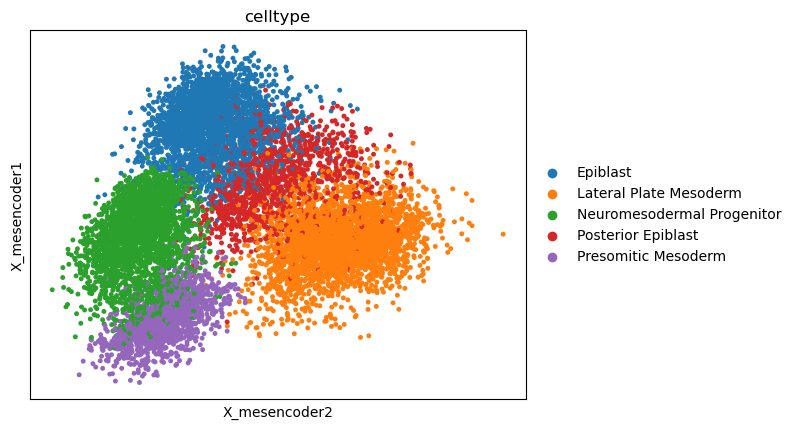

In [5]:
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                color = 'celltype', size = 50, show = False)
plt.gca().invert_yaxis(); plt.show()

inferring a principal tree --> parameters used 
    50 principal points, sigma = 0.05, lambda = 10000.0, metric = euclidean
    fitting:   2%|▏         | 1/50 [00:01<01:22,  1.69s/it]
    converged
    finished (0:00:01) 

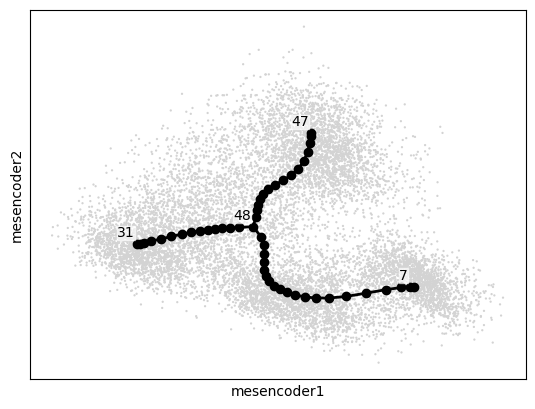

--> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.


In [6]:
scf.tl.tree(adata, method = 'ppt', Nodes = 50,
            ppt_lambda = 1e4, ppt_sigma = .05,
            use_rep = 'X_mesencoder', seed = 1,
            plot = True, basis = 'mesencoder')

In [7]:
scf.tl.root(adata, 31)

node 31 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.


In [8]:
scf.tl.pseudotime(adata)

projecting cells onto the principal graph
    finished (0:00:08) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.


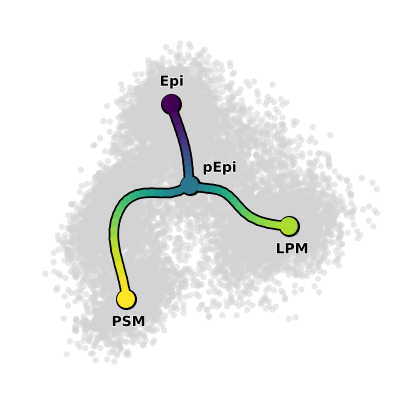

In [9]:
pad = .05
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
scf.pl.trajectory(adata, basis = 'mesencoder', dimensions = [1, 0],
                  size = 80, alpha = .5, frameon = False, show = False,
                  ax = ax)
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                color = 'celltype', size = 80, alpha = 0,
                legend_loc = 'on data', legend_fontoutline = 1,
                frameon = False, show = False, ax = ax)
ax.set_title(''); ax.invert_yaxis()

xlim = ax.get_xlim(); ylim = ax.get_ylim()
xlim = (xlim[0], xlim[1] - .375)
xpad = pad * (xlim[1] - xlim[0])
ypad = pad * (ylim[1] - ylim[0])
ax.set_xlim(xlim[0] - xpad, xlim[1] + xpad)
ax.set_ylim(ylim[0] - ypad, ylim[1] + ypad)

label_dict = {
    'Epiblast'                   : 'Epi',
    'Lateral Plate Mesoderm'     : 'LPM',
    'Neuromesodermal Progenitor' : '',
    'Posterior Epiblast'         : 'pEpi',
    'Presomitic Mesoderm'        : 'PSM'}

pos_dict = {
    'Epiblast'                   : (.025, -.285),
    'Lateral Plate Mesoderm'     : (.2, .165),
    'Posterior Epiblast'         : (.035, -.035),
    'Presomitic Mesoderm'        : (-.065, .165)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])
        label.set_zorder(1000)
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_out, 'trajectories.pdf')
plt.savefig(fn, bbox_inches = 'tight')